# 01 — Explore the Data

**Prerequisite:** notebook 00 ran clean (environment OK, `data/patches_31.npz` built and verified).

This notebook looks at the data the model will train on. Nothing here is decoration: every plot
answers a question that affects how the analysis must be designed, and several of them guard
against mistakes that would *silently* invalidate results.

Concepts in depth: [PRIMER §2–3](../docs/PRIMER.md#2-the-data).

In [1]:
# --- Standard opening: locate project root, import, load the patch file -----
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt

d = np.load(ROOT / "data" / "patches_31.npz")
patches = d["patches"]   # (N, 31, 31) float32 -- RAW charge, one window per labelled pixel
cls     = d["cls"]       # (N,) int8   -- 0 = track (mu/pi/p/K), 1 = shower (e/gamma/pi0)
pid     = d["pid"]       # (N,) int32  -- raw PDG code of the labelling particle
efrac   = d["efrac"]     # (N,) float  -- that particle's energy share at the centre pixel (0-1)
ke      = d["ke_mev"]    # (N,) float  -- its kinetic energy in MeV
flavour = d["flavour"]   # (N,) int8   -- 0 = nu_e event, 1 = nu_mu event
split   = d["split"]     # (N,) int8   -- 0 train / 1 val / 2 test (assigned per archive)

# A fixed random seed makes every "random" selection below reproducible:
# you and I will see the same patches, and the text can refer to them.
rng = np.random.default_rng(3)

# Total charge per patch -- used below to select patches with enough activity to *see*.
tot = patches.reshape(len(patches), -1).sum(axis=1)

print(f"{len(patches):,} patches   track {np.mean(cls==0):.3f} / shower {np.mean(cls==1):.3f}")

415,509 patches   track 0.422 / shower 0.578


### ✅ What you should see

`415,509 patches   track 0.425 / shower 0.575`. A near-balanced two-class problem — which did not
happen by accident, as the class-balance cell below shows.

## 1. What the model sees

Each patch is a 31×31 crop of one anode's `charge[channel, tick]` image — wire number on one axis,
drift time on the other — centred on the pixel whose identity we ask the model to decide. Charge
spans **four decades**, so we display `log1p(charge)`; on a linear scale only the few brightest
pixels would be visible.

The selection below keeps *clean* labels (`efrac > 0.99`: one particle deposited essentially all the
centre-pixel energy) and patches with enough total charge to see structure.

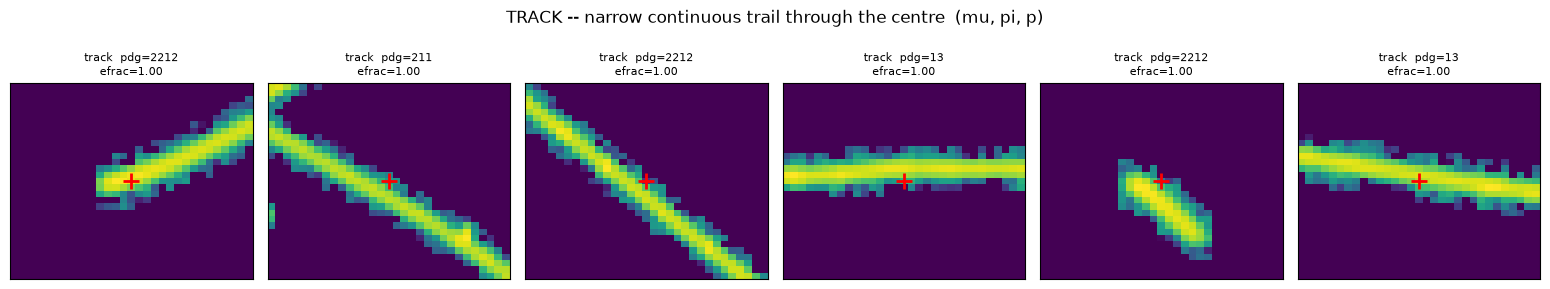

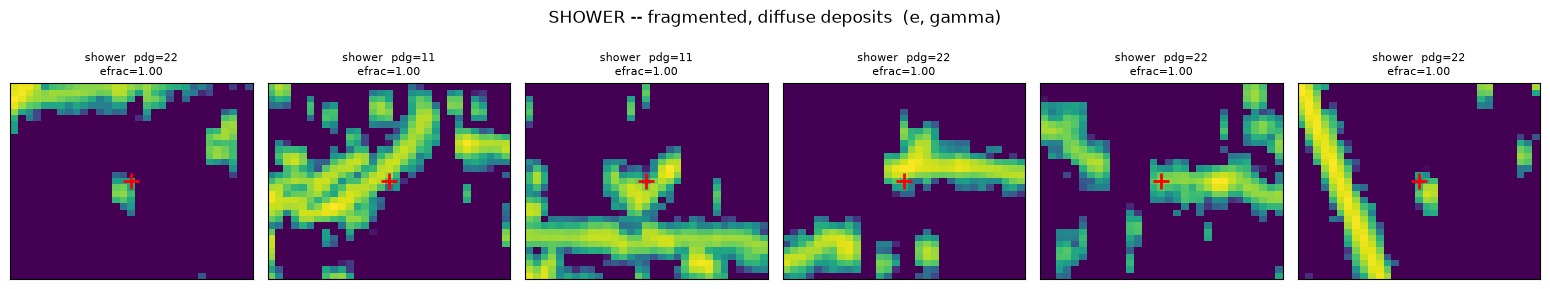

In [2]:
def show_patches(idxs, title):
    """Display a row of patches. Red + marks the centre pixel -- the one being classified."""
    fig, axes = plt.subplots(1, len(idxs), figsize=(2.6 * len(idxs), 2.9))
    for ax, i in zip(axes, idxs):
        # .T + origin="lower": channel on x, tick on y, matching the detector convention
        ax.imshow(np.log1p(patches[i]).T, origin="lower", cmap="viridis", aspect="auto")
        ax.plot(15, 15, "r+", ms=12, mew=2)                      # the labelled pixel
        ax.set_title(f"{'track' if cls[i]==0 else 'shower'}  pdg={pid[i]}\nefrac={efrac[i]:.2f}",
                     fontsize=8)
        ax.set_xticks([]); ax.set_yticks([])
    fig.suptitle(title); fig.tight_layout(); plt.show()

# Clean labels + visible charge, then 6 random examples of each class
clean = (efrac > 0.99) & (tot > np.percentile(tot, 60))
show_patches(rng.choice(np.flatnonzero(clean & (cls == 0)), 6, replace=False),
             "TRACK -- narrow continuous trail through the centre  (mu, pi, p)")
show_patches(rng.choice(np.flatnonzero(clean & (cls == 1)), 6, replace=False),
             "SHOWER -- fragmented, diffuse deposits  (e, gamma)")

### ✅ What you should see, and what to notice

- **Tracks** are thin, connected, roughly straight streaks passing through the red `+`. The PDG
  codes read 13 (μ), 211 (π), 2212 (p) — exactly the track-like species.
- **Showers** are patchy clusters of disconnected blobs — PDG 11 (e) and 22 (γ), the EM cascade
  species.
- **The red `+` always sits on charge.** That is the centring guarantee verified in notebook 00.

**The most instructive panels are the messy shower ones**: in several, the labelled centre pixel
sits on a small EM blob while an unrelated *track* also crosses the patch. That is not an error —
the label belongs to the **centre pixel only**, and the rest of the patch is context. It is also
why this task is genuinely hard: the model must work out *which structure the centre pixel belongs
to*, not just "is there a track anywhere in view". Real neutrino events are busy.

Change the seed in the first cell (`default_rng(3)` → any integer) and re-run to see more examples.

## 2. Why both neutrino flavours are pooled

A model shown 95% one class can score 95% "accuracy" by always guessing it — so **class balance**
matters before any score means anything.

In [3]:
# Shower fraction per event flavour, and pooled.
for name, m in (("nu_e  events", flavour == 0),
                ("nu_mu events", flavour == 1),
                ("pooled      ", np.ones(len(cls), bool))):
    print(f"{name}:  shower {np.mean(cls[m]==1):.2f} / track {np.mean(cls[m]==0):.2f}"
          f"   ({m.sum():,} patches)")

nu_e  events:  shower 0.85 / track 0.15   (168,827 patches)
nu_mu events:  shower 0.40 / track 0.60   (246,682 patches)
pooled      :  shower 0.58 / track 0.42   (415,509 patches)


### ✅ What you should see

νe events are ~**80/20 shower-dominated** (the primary electron showers, and showers produce many
labelled pixels); νμ events are ~**36/64 track-dominated** (the primary muon is one long track).
Each alone is a skewed problem; **pooled they land near 57/43** — close enough to balanced that
accuracy-style intuitions do not mislead, with no reweighting tricks needed.

## 3. Label quality — a handle nobody else has

A pixel's label comes from the particle that deposited the **most** energy there. But *most* is not
*all*: where a track crosses a shower, two particles contribute, and the label is nearly a coin
flip. The dataset records this as `efrac` — the labelling particle's energy share at the centre
pixel. `efrac = 1.0` means unambiguous; `efrac ≈ 0.5` means two particles contributed equally.

The published studies in this area have no equivalent quantity. It gives this project a measurement
nobody else can make: **performance as a function of label purity** (plan §2.4).

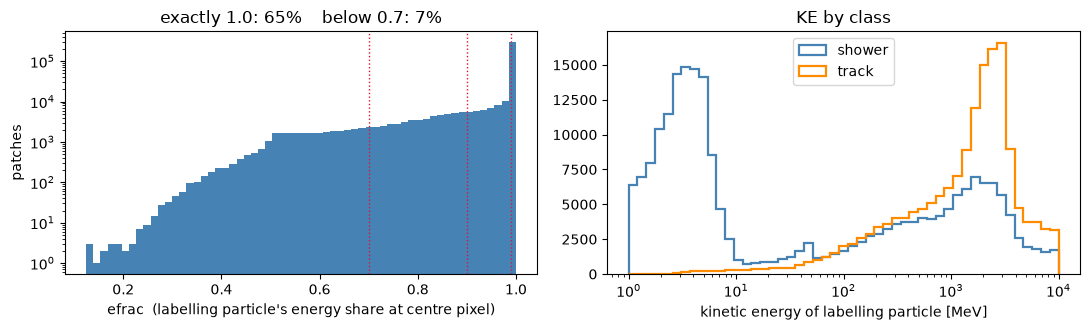

In [4]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.4))

# Left: the purity distribution. Log y-axis, because clean labels dominate.
a1.hist(efrac, bins=60, color="steelblue")
a1.set_yscale("log")
a1.set_xlabel("efrac  (labelling particle's energy share at centre pixel)")
a1.set_ylabel("patches")
for q in (0.7, 0.9, 0.99):
    a1.axvline(q, color="crimson", ls=":", lw=1)       # guide lines at useful cuts
a1.set_title(f"exactly 1.0: {np.mean(efrac >= 0.999):.0%}    below 0.7: {np.mean(efrac < 0.7):.0%}")

# Right: kinetic energy of the labelling particle, split by class. Log x -- it spans MeV to GeV.
a2.hist([ke[cls == 0], ke[cls == 1]], bins=np.logspace(0, 4, 50),
        label=["track", "shower"], color=["darkorange", "steelblue"],
        histtype="step", lw=1.6)
a2.set_xscale("log")
a2.set_xlabel("kinetic energy of labelling particle [MeV]")
a2.legend(); a2.set_title("KE by class")
fig.tight_layout(); plt.show()

### ✅ What you should see

- **Left:** a spike at 1.0 — about **half** the labels are perfectly clean — then a falling tail.
  Roughly **one patch in ten has efrac < 0.7**, i.e. a genuinely contested label. That 10% puts a
  ceiling on any model's achievable score; no architecture can beat labels that are themselves
  ambiguous. It also means *label purity is a variable to study, not noise to ignore*.
- **Right:** shower particles cluster at low KE (the many soft photons and electrons of a cascade);
  track particles extend to higher KE. Energy and class are correlated — worth remembering whenever
  a result is quoted integrated over energy.

What does an ambiguous label *look like*? Exactly what the physics suggests — overlap:

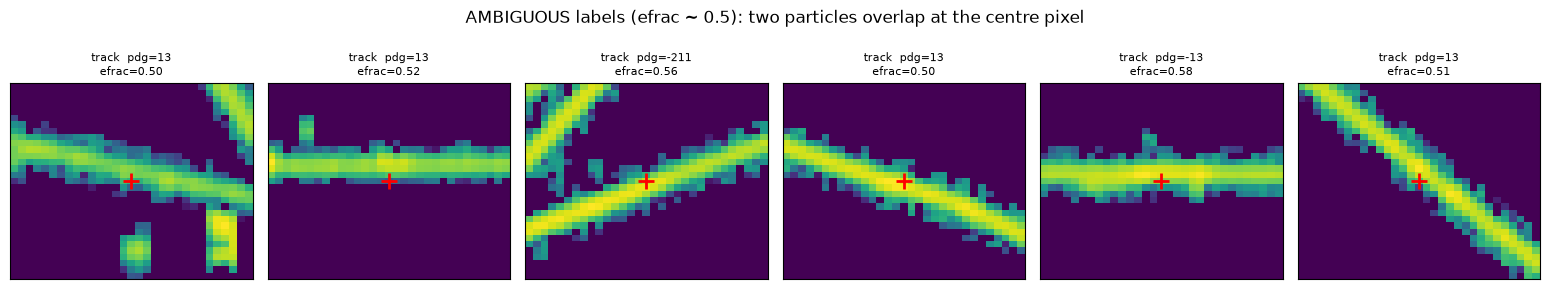

In [5]:
# Patches whose centre-pixel label was nearly a coin flip (two particles ~equal energy).
ambiguous = (efrac > 0.4) & (efrac < 0.6) & (tot > np.percentile(tot, 60))
show_patches(rng.choice(np.flatnonzero(ambiguous), 6, replace=False),
             "AMBIGUOUS labels (efrac ~ 0.5): two particles overlap at the centre pixel")

### ✅ What you should see

Busy patches where a track crosses or touches shower activity right at the `+`. The assigned class
(whatever won the energy contest) is printed in each title — and for several you could argue the
other way. **This is what a 50% label looks like physically**, and it is why reporting performance
*versus* efrac is more honest than one integrated number.

## 4. ⚠️ Deep dive — the negative track ID trap *(optional; reads one raw archive, ~1 min)*

The patch file you loaded already handled this correctly. But anyone who ever touches the **raw**
campaign files must know it, because getting it wrong produces a dataset that *looks* fine and is
~90% mislabelled — with no error message anywhere.

Background: Geant4 produces enormous numbers of low-energy secondaries inside an EM cascade.
Storing each is wasteful, so the simulation runs with `keepEMShowerDaughters = false` — cascade
secondaries are not stored individually, and their energy deposits are recorded under the **negated
track ID of the shower's ancestor**. The particle list, meanwhile, holds only positive IDs.

In [7]:
# Read ONE raw archive and measure the effect directly.
import tarfile, tempfile, glob, os, h5py
from qmllar.extract import BASE

# Unpack the first nu_e archive into RAM-backed scratch (/dev/shm -- fast, auto-cleaned).
arch = sorted(glob.glob(f"{BASE}/fdhd_sparse_nue_truthlabel/001/*.tgz"))[0]
tmp = tempfile.mkdtemp(dir="/dev/shm")
with tarfile.open(arch) as tf:
    if hasattr(tarfile, "data_filter"):
        tf.extractall(tmp, filter="data")
    else:
        tf.extractall(tmp)

# The truth file: the Geant4 particle list for each event (track IDs all positive).
truth = glob.glob(f"{tmp}/sparse/*trackid_pid_map.h5")[0]
with h5py.File(truth) as f:
    mc_ids = f["/1/mcpart/track_ids"][:]          # event "1", all stored particles

# The image file: per-pixel track IDs for anode 0 of the same event.
pix = glob.glob(f"{tmp}/sparse/*pixeldata-anode0.h5")[0]
with h5py.File(pix) as f:
    px_ids = f["/1/frame_trackid_1st/features"][:].astype(int)

print(f"pixel track IDs range        : {px_ids.min()} .. {px_ids.max()}")
print(f"pixels with NEGATIVE id      : {np.mean(px_ids < 0):.1%}")
print()
# The join, done wrong and done right:
print(f"raw  lookup -- pixels whose id is NOT in the particle list: "
      f"{np.mean(~np.isin(px_ids, mc_ids)):.1%}")
print(f"abs() lookup -- pixels whose id is NOT in the particle list: "
      f"{np.mean(~np.isin(np.abs(px_ids), mc_ids)):.1%}")

import shutil; shutil.rmtree(tmp)                  # clean up the scratch copy

pixel track IDs range        : -970 .. 1004
pixels with NEGATIVE id      : 89.8%

raw  lookup -- pixels whose id is NOT in the particle list: 89.8%
abs() lookup -- pixels whose id is NOT in the particle list: 0.0%


### ✅ What you should see

- ~**90% of pixel IDs are negative** in this event, and with a raw join ~**90% of pixels find no
  particle** — they would fall into an "unknown" class, silently.
- With `abs()`, **0.0% miss**: every pixel resolves to its shower ancestor, which is the correct
  physics (the deposit *belongs* to that cascade).

The lesson generalises beyond this dataset: **the worst data bugs don't crash — they return
plausible numbers.** The defence is always the same: know the expected value in advance (here,
"shower-dominated νe events") and check against it.

## 5. Charge normalisation — settle it before training anything

The quantum circuit turns a pixel value into a rotation angle, and rotation gates saturate:
`arctan(x)` is within 1% of π/2 for any x ≳ 10. Raw charge has a **median of ~720** — so on raw
input, nearly all charged pixels encode to the *same angle* and the circuit is fed almost no
information. The model would still train and still print a score; the score would just measure your
normalisation choice. ([PRIMER §3.4](../docs/PRIMER.md#34-charge-normalisation))

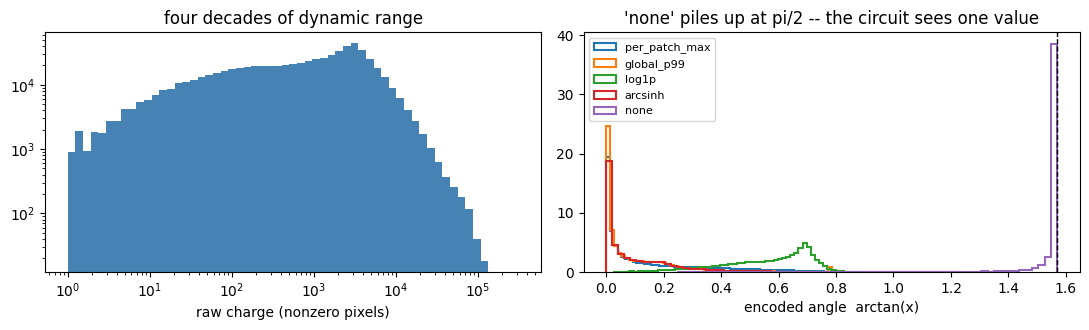

raw charge: 81.9% of charged pixels encode within 1% of pi/2


In [ ]:
from qmllar.preprocess import normalise, NORM_MODES   # the project's normalisation options

sample = patches[rng.choice(len(patches), 4000, replace=False)]   # 4k patches is plenty here
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.4))

# Left: the raw dynamic range (nonzero pixels; log-log).
nz = sample[sample > 0]
a1.hist(nz, bins=np.logspace(0, 5.5, 60), color="steelblue")
a1.set_xscale("log"); a1.set_yscale("log")
a1.set_xlabel("raw charge (nonzero pixels)")
a1.set_title("four decades of dynamic range")

# Right: what each normalisation does to the ENCODED ANGLE arctan(x).
for m in NORM_MODES:
    x = normalise(sample, m)
    xnz = x[x > 0]
    a2.hist(np.arctan(xnz), bins=60, histtype="step", lw=1.5, label=m, density=True)
a2.axvline(np.pi / 2, color="k", ls="--", lw=1)        # the saturation angle
a2.set_xlabel("encoded angle  arctan(x)")
a2.legend(fontsize=8)
a2.set_title("'none' piles up at pi/2 -- the circuit sees one value")
fig.tight_layout(); plt.show()

# The headline number:
raw_angles = np.arctan(nz)
print(f"raw charge: {np.mean(raw_angles > 0.99 * np.pi/2):.1%} of charged pixels "
      f"encode within 1% of pi/2")

### ✅ What you should see

- **Left:** charge from single digits to >10⁵ — four decades.
- **Right:** every real normalisation spreads angles across the usable range; **`none` piles up
  against the π/2 line**, and the printout confirms it: **~84%** of charged pixels within 1% of
  saturation.

Consequences for the analysis (these are rules, not suggestions):

1. **Never train on raw charge.**
2. Normalisation is a *model choice* to be **swept** — `arctan` on log-scaled charge is a different
   model from `arctan` on max-scaled charge.
3. Whatever is chosen must be **identical for the quantum and classical arms**, or the comparison
   is void.

---

## Where to next

→ **Notebook 02** — the quantum layer itself: what the circuit is, proof our implementation is
correct, and watching it transform one of these patches into feature maps.